In [21]:
import os, json, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import kruskal, mannwhitneyu, chi2_contingency
from sklearn.model_selection import StratifiedGroupKFold, cross_val_predict
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.feature_selection import mutual_info_classif
from sklearn.inspection import permutation_importance
from sklearn.metrics import f1_score, classification_report

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 100)
pd.set_option("display.width", 200)
sns.set_theme(style="whitegrid")

DATA_DIR = r"C:\Users\minsa_\Downloads"      # folder with Cleaned_Dataset.csv
OUT_DIR = DATA_DIR
RANDOM_STATE = 42
CLASS_ORDER = ["Normal", "Folds", "Guttata", "FECD/Endothelial"]
SEV_ORDER = ["Mild", "Moderate+Severe"]

df = pd.read_csv(os.path.join(DATA_DIR, "Cleaned_Dataset.csv"))
print("Loaded:", df.shape)
df["Target_Class"].value_counts().reindex(CLASS_ORDER)

Loaded: (1048, 31)


Target_Class
Normal              504
Folds               324
Guttata              84
FECD/Endothelial    136
Name: count, dtype: int64

In [22]:
sgkf = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
train_idx, test_idx = next(sgkf.split(df, df["Target_Class"], groups=df["Donor_Group"]))
df["Split"] = "train"
df.loc[test_idx, "Split"] = "test"

print("Donors in both splits:",
      len(set(df.loc[df.Split == "train", "Donor_Group"]) & set(df.loc[df.Split == "test", "Donor_Group"])))
pd.crosstab(df["Target_Class"], df["Split"]).reindex(CLASS_ORDER)

Donors in both splits: 0


Split,test,train
Target_Class,,
Normal,101,403
Folds,65,259
Guttata,17,67
FECD/Endothelial,27,109


In [23]:
X = pd.DataFrame(index=df.index)

# raw Konan + donor
for c in ["ECD_CD_cells_per_mm2", "CV", "HEX_percent", "SD", "Total_Cell_Count",
          "Donor_Age", "Eye_Right", "Death_to_Preservation_Min"]:
    X[c] = df[c]

# engineered Konan
X["ECD_Deficit"] = (2500 - df["ECD_CD_cells_per_mm2"]).clip(lower=0)

norm = (df["Split"] == "train") & (df["Target_Class"] == "Normal") \
       & df["ECD_CD_cells_per_mm2"].notna() & df["Donor_Age"].notna()
slope, intercept = np.polyfit(df.loc[norm, "Donor_Age"], df.loc[norm, "ECD_CD_cells_per_mm2"], 1)
print(f"Age norm (train Normal): expected ECD = {intercept:.0f} + ({slope:.2f}) x age")
X["ECD_Age_Residual"] = df["ECD_CD_cells_per_mm2"] - (intercept + slope * df["Donor_Age"])

X["Pleomorphism_Index"] = df["CV"] * (100 - df["HEX_percent"]) / 100
X["log_SD"] = np.log1p(df["SD"])
X["SD_x_CV"] = df["SD"] * df["CV"] / 100
X["Low_Cell_Count"] = (df["Total_Cell_Count"] < 50).astype(float).where(df["Total_Cell_Count"].notna())

# encoded donor fields + missingness indicators
X["Donor_Sex_Male"] = df["Donor_Sex_Clean"].map({"Male": 1, "Female": 0})
X["Lens_Pseudophakic"] = df["Lens_Status_Clean"].map({"Pseudophakic": 1, "Aphakic": 1, "Phakic": 0})
X["Konan_Missing"] = df["ECD_CD_cells_per_mm2"].isna().astype(int)
X["Form_Missing"] = df["Donor_Sex_Clean"].isna().astype(int)

FEATURES = X.columns.tolist()
FEATURE_GROUP = {
    **{c: "Konan (raw)" for c in ["ECD_CD_cells_per_mm2", "CV", "HEX_percent", "SD", "Total_Cell_Count"]},
    **{c: "Konan (engineered)" for c in ["ECD_Deficit", "ECD_Age_Residual", "Pleomorphism_Index",
                                         "log_SD", "SD_x_CV", "Low_Cell_Count"]},
    **{c: "Donor" for c in ["Donor_Age", "Eye_Right", "Donor_Sex_Male", "Lens_Pseudophakic",
                            "Death_to_Preservation_Min"]},
    **{c: "Missingness" for c in ["Konan_Missing", "Form_Missing"]},
}
print(len(FEATURES), "candidate features")

data = pd.concat([df[["Tissue_ID", "Donor_Group", "Split", "Target_Class", "Target_Severity"]], X], axis=1)
train = data[data["Split"] == "train"].reset_index(drop=True)
train[FEATURES].describe().T.round(2)

Age norm (train Normal): expected ECD = 3112 + (-7.10) x age
18 candidate features


,count,mean,std,min,25%,50%,75%,max
ECD_CD_cells_per_mm2,797.0,2597.58,439.45,676.00,2342.00,2577.00,2857.00,4484.00
CV,797.0,38.29,4.92,24.00,35.00,38.00,41.00,74.00
HEX_percent,797.0,53.76,6.60,27.00,50.00,54.00,58.00,76.00
SD,796.0,153.10,46.51,86.00,127.00,145.00,165.00,753.00
Total_Cell_Count,760.0,107.04,15.99,12.00,104.00,108.00,113.00,169.00
Donor_Age,835.0,59.67,10.95,15.00,54.00,62.00,68.00,78.00
Eye_Right,838.0,0.72,0.45,0.00,0.00,1.00,1.00,1.00
Death_to_Preservation_Min,463.0,130.40,49.41,20.00,100.00,125.00,145.00,325.00
ECD_Deficit,797.0,118.76,239.32,0.00,0.00,0.00,158.00,1824.00
ECD_Age_Residual,795.0,-91.03,432.15,-2066.33,-333.95,-96.57,151.78,1535.66


In [24]:
def cliffs_delta(a, b):
    return 2 * mannwhitneyu(a, b).statistic / (len(a) * len(b)) - 1

binary_feats = [c for c in FEATURES if set(train[c].dropna().unique()) <= {0, 1}]
cont_feats = [c for c in FEATURES if c not in binary_feats]

# continuous: Kruskal-Wallis + Cliff's delta (each class vs rest)
rows = []
for col in cont_feats:
    groups = [train.loc[train["Target_Class"] == c, col].dropna() for c in CLASS_ORDER]
    h, p = kruskal(*groups)
    r = {"Feature": col, "Kruskal_H": round(h, 1), "p_value": p}
    for cls in CLASS_ORDER:
        inside = train.loc[train["Target_Class"] == cls, col].dropna()
        outside = train.loc[train["Target_Class"] != cls, col].dropna()
        r[f"d_{cls}"] = round(cliffs_delta(inside, outside), 2)
    rows.append(r)
uni_cont = pd.DataFrame(rows)
uni_cont["p_adj"] = np.minimum(uni_cont["p_value"] * len(FEATURES), 1)   # Bonferroni
print("Continuous features - Kruskal-Wallis + Cliff's delta (class vs rest)")
print("|d| <0.15 negligible, <0.33 small, <0.47 medium, >=0.47 large")
display(uni_cont.sort_values("Kruskal_H", ascending=False).round(4))

# binary: Chi-square + Cramer's V
rows = []
for col in binary_feats:
    ct = pd.crosstab(train[col], train["Target_Class"])
    chi2, p, dof, _ = chi2_contingency(ct)
    cramers_v = np.sqrt(chi2 / (ct.values.sum() * (min(ct.shape) - 1)))
    rates = train.groupby("Target_Class")[col].mean().reindex(CLASS_ORDER).round(2)
    rows.append({"Feature": col, "Chi2": round(chi2, 1), "p_value": p,
                 "Cramers_V": round(cramers_v, 3), **{f"rate_{k}": v for k, v in rates.items()}})
uni_bin = pd.DataFrame(rows)
uni_bin["p_adj"] = np.minimum(uni_bin["p_value"] * len(FEATURES), 1)
print("\nBinary features - Chi-square + Cramer's V (rate = share of 1s per class)")
display(uni_bin.sort_values("Chi2", ascending=False).round(4))

Continuous features - Kruskal-Wallis + Cliff's delta (class vs rest)
|d| <0.15 negligible, <0.33 small, <0.47 medium, >=0.47 large


,Feature,Kruskal_H,p_value,d_Normal,d_Folds,d_Guttata,d_FECD/Endothelial,p_adj
7,ECD_Deficit,350.6,0.0000,-0.26,-0.20,-0.03,0.96,0.0000
0,ECD_CD_cells_per_mm2,260.4,0.0000,0.26,0.22,-0.01,-0.96,0.0000
8,ECD_Age_Residual,256.7,0.0000,0.22,0.26,-0.00,-0.96,0.0000
3,SD,189.5,0.0000,-0.30,-0.09,-0.01,0.82,0.0000
10,log_SD,189.5,0.0000,-0.30,-0.09,-0.01,0.82,0.0000
11,SD_x_CV,113.8,0.0000,-0.27,-0.01,-0.03,0.62,0.0000
5,Donor_Age,27.5,0.0000,-0.19,0.13,-0.05,0.20,0.0001
9,Pleomorphism_Index,17.7,0.0005,-0.16,0.14,-0.04,0.11,0.0093
1,CV,17.1,0.0007,-0.15,0.13,-0.07,0.11,0.0120
4,Total_Cell_Count,16.4,0.0010,0.13,-0.02,-0.03,-0.22,0.0171



Binary features - Chi-square + Cramer's V (rate = share of 1s per class)


,Feature,Chi2,p_value,Cramers_V,rate_Normal,rate_Folds,rate_Guttata,rate_FECD/Endothelial,p_adj
3,Lens_Pseudophakic,27.3,0.0000,0.245,0.05,0.01,0.06,0.22,0.0001
4,Konan_Missing,18.8,0.0003,0.150,0.08,0.02,0.00,0.03,0.0054
5,Form_Missing,17.2,0.0006,0.143,0.41,0.46,0.49,0.63,0.0116
1,Low_Cell_Count,16.5,0.0009,0.147,0.01,0.01,0.00,0.06,0.0159
0,Eye_Right,9.8,0.0207,0.108,0.73,0.66,0.70,0.81,0.3718
2,Donor_Sex_Male,2.7,0.4421,0.077,0.71,0.65,0.65,0.62,1.0000


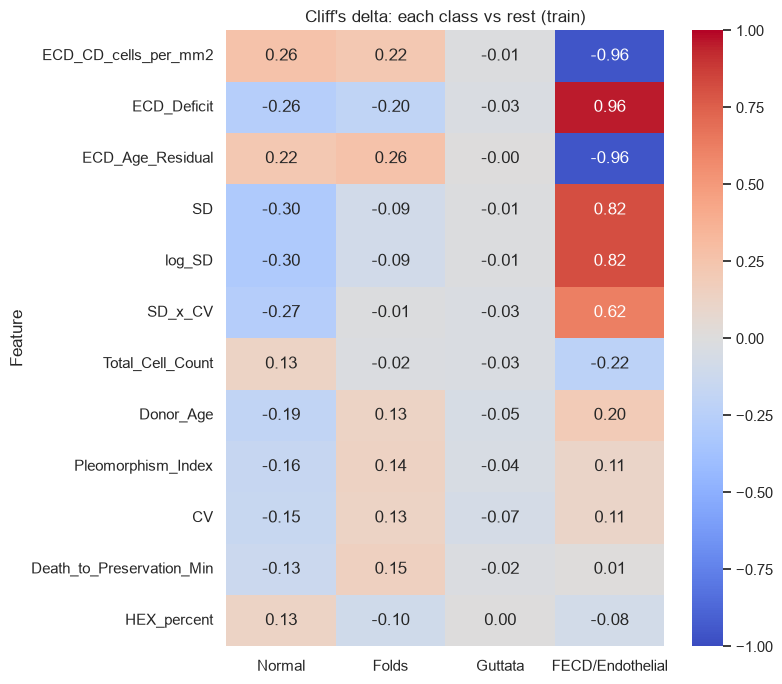

In [25]:
heat = uni_cont.set_index("Feature")[[f"d_{c}" for c in CLASS_ORDER]]
heat.columns = CLASS_ORDER
heat = heat.reindex(heat.abs().max(axis=1).sort_values(ascending=False).index)

plt.figure(figsize=(8, 7))
sns.heatmap(heat, annot=True, fmt=".2f", cmap="coolwarm", center=0, vmin=-1, vmax=1)
plt.title("Cliff's delta: each class vs rest (train)")
plt.tight_layout(); plt.show()

In [26]:
Xi = train[FEATURES].fillna(train[FEATURES].median())
mi_all = pd.Series(mutual_info_classif(Xi, train["Target_Class"], random_state=RANDOM_STATE), index=FEATURES)
mi_ovr = pd.DataFrame({c: mutual_info_classif(Xi, (train["Target_Class"] == c).astype(int),
                                              random_state=RANDOM_STATE) for c in CLASS_ORDER},
                      index=FEATURES)
mi_table = mi_ovr.assign(MI_all=mi_all).sort_values("MI_all", ascending=False).round(3)
mi_table

,Normal,Folds,Guttata,FECD/Endothelial,MI_all
ECD_CD_cells_per_mm2,0.084,0.091,0.015,0.273,0.331
ECD_Deficit,0.085,0.054,0.034,0.270,0.319
ECD_Age_Residual,0.047,0.053,0.013,0.243,0.268
SD,0.038,0.029,0.001,0.166,0.179
log_SD,0.023,0.013,0.015,0.160,0.164
SD_x_CV,0.042,0.000,0.012,0.104,0.104
Low_Cell_Count,0.033,0.045,0.011,0.016,0.066
Total_Cell_Count,0.013,0.011,0.005,0.036,0.043
Death_to_Preservation_Min,0.022,0.001,0.003,0.036,0.040
Form_Missing,0.013,0.006,0.001,0.000,0.018


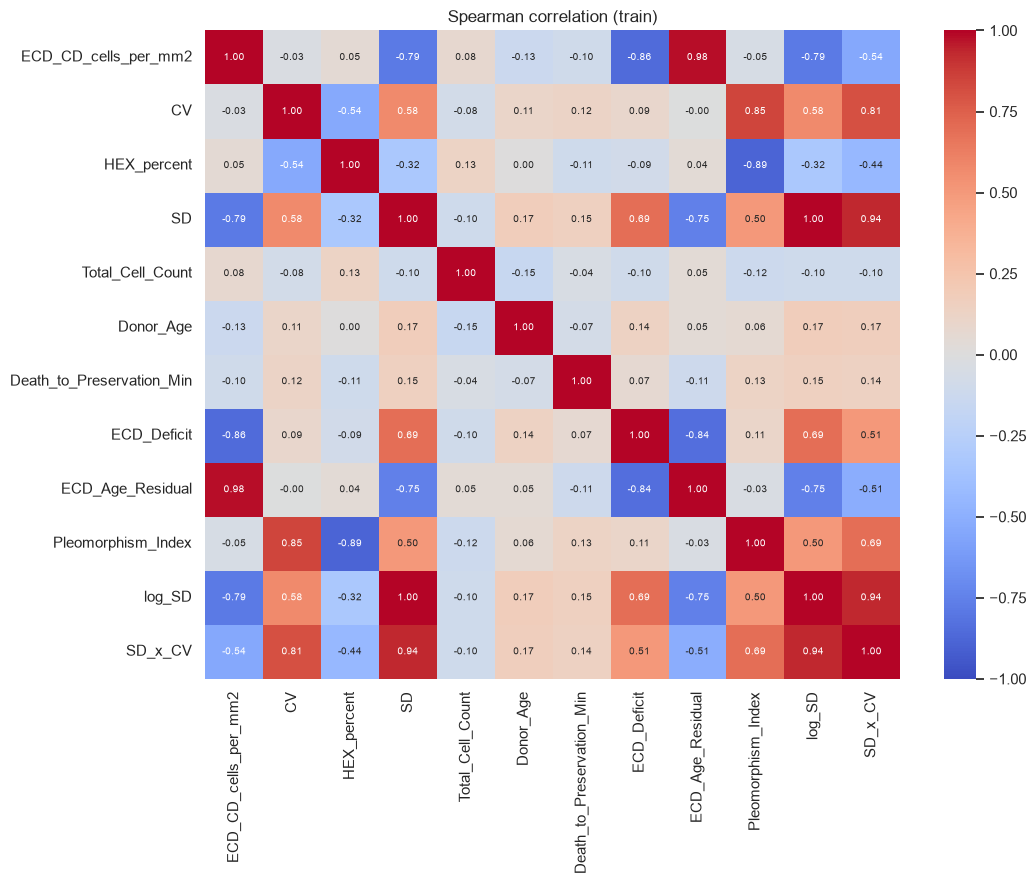

Pairs with |rho| >= 0.8:


,,rho
SD,log_SD,1.00
ECD_CD_cells_per_mm2,ECD_Age_Residual,0.98
SD,SD_x_CV,0.94
log_SD,SD_x_CV,0.94
HEX_percent,Pleomorphism_Index,-0.89
ECD_CD_cells_per_mm2,ECD_Deficit,-0.86
CV,Pleomorphism_Index,0.85
ECD_Deficit,ECD_Age_Residual,-0.84
CV,SD_x_CV,0.81



VIF, all continuous features (>10 = severe multicollinearity):


,VIF
ECD_CD_cells_per_mm2,314.7
ECD_Age_Residual,259.8
SD,256.0
log_SD,216.5
Pleomorphism_Index,171.8
SD_x_CV,162.4
CV,136.5
HEX_percent,62.0
Donor_Age,8.7
ECD_Deficit,6.2


In [27]:
corr = train[cont_feats].corr(method="spearman")
plt.figure(figsize=(11, 9))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0, vmin=-1, vmax=1, annot_kws={"size": 7})
plt.title("Spearman correlation (train)"); plt.tight_layout(); plt.show()

up = corr.where(np.triu(np.ones(corr.shape), 1).astype(bool)).stack()
print("Pairs with |rho| >= 0.8:")
display(up[up.abs() >= 0.8].sort_values(key=abs, ascending=False).round(2).to_frame("rho"))

def vif_table(cols):
    Z = train[cols].fillna(train[cols].median())
    vif = np.diag(np.linalg.pinv(Z.corr().values))      # VIF_i = [R^-1]_ii
    return pd.Series(vif, index=cols).sort_values(ascending=False).round(1)

print("\nVIF, all continuous features (>10 = severe multicollinearity):")
vif_table(cont_feats).to_frame("VIF")

In [28]:
REDUNDANT = ["log_SD", "SD_x_CV", "ECD_Age_Residual", "Pleomorphism_Index"]
REDUCED = [c for c in FEATURES if c not in REDUNDANT]
print("Dropped as redundant:", REDUNDANT)
print("\nVIF after reduction:")
vif_table([c for c in REDUCED if c in cont_feats]).to_frame("VIF")

Dropped as redundant: ['log_SD', 'SD_x_CV', 'ECD_Age_Residual', 'Pleomorphism_Index']

VIF after reduction:


,VIF
SD,9.0
ECD_Deficit,4.8
ECD_CD_cells_per_mm2,3.7
CV,3.2
HEX_percent,1.4
Total_Cell_Count,1.2
Donor_Age,1.1
Death_to_Preservation_Min,1.0


Permutation importance (drop in macro-F1), donor-grouped 5-fold CV on train


,Perm_Importance,Std_across_folds,Positive_in_folds
ECD_CD_cells_per_mm2,0.0997,0.0288,5
ECD_Deficit,0.0931,0.0217,5
Donor_Age,0.0153,0.0160,4
CV,0.0121,0.0209,3
HEX_percent,0.0087,0.0222,3
Death_to_Preservation_Min,0.0053,0.0112,4
Total_Cell_Count,0.0046,0.0195,4
Konan_Missing,0.0037,0.0045,4
Eye_Right,0.0023,0.0066,3
Lens_Pseudophakic,0.0005,0.0019,1


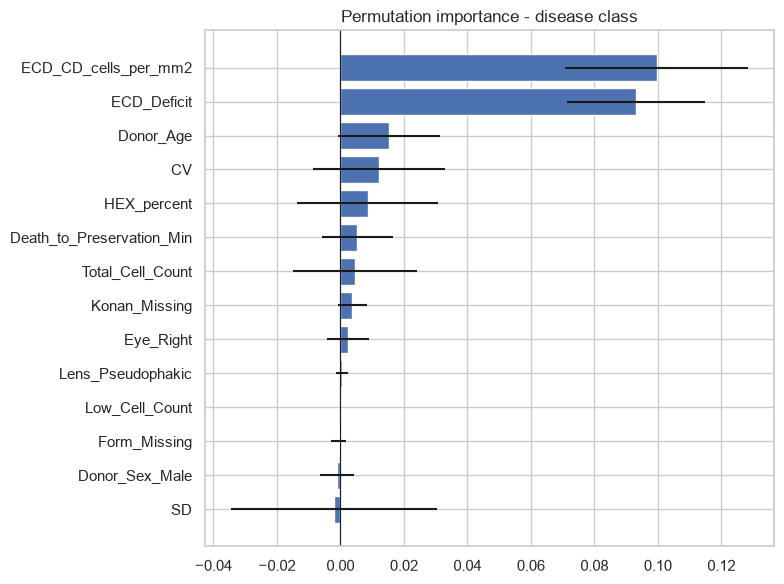

In [29]:
cv = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

def rf_pipe():
    return Pipeline([("imp", SimpleImputer(strategy="median")),
                     ("rf", RandomForestClassifier(n_estimators=300, min_samples_leaf=3,
                                                   class_weight="balanced_subsample",
                                                   random_state=RANDOM_STATE, n_jobs=-1))])

def grouped_perm_importance(data, cols, target, scoring="f1_macro", n_repeats=10):
    imps = []
    for tr, va in cv.split(data, data[target], groups=data["Donor_Group"]):
        m = rf_pipe().fit(data.iloc[tr][cols], data.iloc[tr][target])
        pi = permutation_importance(m, data.iloc[va][cols], data.iloc[va][target],
                                    scoring=scoring, n_repeats=n_repeats,
                                    random_state=RANDOM_STATE, n_jobs=-1)
        imps.append(pi.importances_mean)
    imps = np.array(imps)
    return pd.DataFrame({"Perm_Importance": imps.mean(0), "Std_across_folds": imps.std(0),
                         "Positive_in_folds": (imps > 0).sum(0)}, index=cols)

perm_cls = grouped_perm_importance(train, REDUCED, "Target_Class").sort_values("Perm_Importance", ascending=False)
print("Permutation importance (drop in macro-F1), donor-grouped 5-fold CV on train")
display(perm_cls.round(4))

plt.figure(figsize=(8, 6))
p = perm_cls.sort_values("Perm_Importance")
plt.barh(p.index, p["Perm_Importance"], xerr=p["Std_across_folds"])
plt.axvline(0, c="k", lw=0.8)
plt.title("Permutation importance - disease class"); plt.tight_layout(); plt.show()

,Normal,Folds,Guttata,FECD/Endothelial
ECD_CD_cells_per_mm2,0.0212,0.0227,0.0260,0.2549
ECD_Deficit,0.0207,0.0082,0.0258,0.2080
Donor_Age,0.0347,0.0369,0.0002,0.0000
Low_Cell_Count,0.0000,-0.0010,0.0000,0.0000
Eye_Right,0.0139,-0.0008,-0.0009,0.0000
HEX_percent,0.0175,-0.0095,0.0120,0.0000
Konan_Missing,0.0035,0.0060,0.0028,0.0000
Lens_Pseudophakic,0.0002,0.0033,0.0000,0.0000
Donor_Sex_Male,-0.0008,-0.0063,0.0222,0.0000
SD,0.0076,-0.0120,0.0263,-0.0015


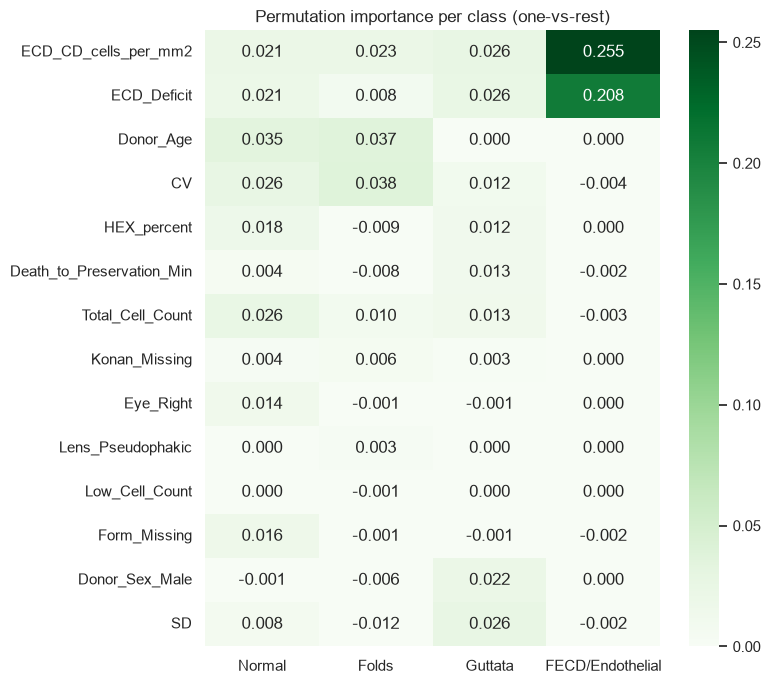

In [30]:
perm_ovr = {}
for cls in CLASS_ORDER:
    t = train.assign(y=(train["Target_Class"] == cls).map({True: cls, False: "Other"}))
    perm_ovr[cls] = grouped_perm_importance(t, REDUCED, "y", n_repeats=5)["Perm_Importance"]
perm_ovr = pd.DataFrame(perm_ovr).round(4)
display(perm_ovr.sort_values("FECD/Endothelial", ascending=False))

plt.figure(figsize=(8, 7))
sns.heatmap(perm_ovr.reindex(perm_cls.index), annot=True, fmt=".3f", cmap="Greens", vmin=0)
plt.title("Permutation importance per class (one-vs-rest)"); plt.tight_layout(); plt.show()

In [31]:
lr = Pipeline([("imp", SimpleImputer(strategy="median")),
               ("sc", StandardScaler()),
               ("lr", LogisticRegression(penalty="l1", solver="saga", C=0.1, max_iter=5000,
                                         class_weight="balanced", random_state=RANDOM_STATE))])
lr.fit(train[REDUCED], train["Target_Class"])
coef = pd.DataFrame(lr.named_steps["lr"].coef_.T, index=REDUCED,
                    columns=lr.named_steps["lr"].classes_)[CLASS_ORDER].round(3)
coef["n_classes_nonzero"] = (coef[CLASS_ORDER] != 0).sum(axis=1)
print("L1 logistic regression coefficients (standardised; 0 = feature dropped)")
coef.sort_values("n_classes_nonzero", ascending=False)

L1 logistic regression coefficients (standardised; 0 = feature dropped)


,Normal,Folds,Guttata,FECD/Endothelial,n_classes_nonzero
Konan_Missing,0.076,-0.105,-0.352,0.397,4
ECD_CD_cells_per_mm2,0.000,0.086,-0.206,-0.221,3
Death_to_Preservation_Min,-0.011,0.056,-0.000,0.001,3
Total_Cell_Count,0.070,0.000,-0.024,0.000,2
Donor_Age,-0.082,0.233,0.000,0.000,2
CV,0.000,0.197,-0.022,0.000,2
Donor_Sex_Male,0.000,-0.035,0.000,0.064,2
Eye_Right,0.080,-0.044,0.000,0.000,2
ECD_Deficit,0.000,-0.077,0.000,2.900,2
HEX_percent,0.069,0.000,0.000,0.000,1


,k,Added_feature,Macro_F1
0,1,ECD_CD_cells_per_mm2,0.474
1,2,ECD_Deficit,0.483
2,3,Donor_Age,0.490
3,4,CV,0.514
4,5,HEX_percent,0.541
5,6,Death_to_Preservation_Min,0.531
6,7,Total_Cell_Count,0.523
7,8,Konan_Missing,0.527
8,9,Eye_Right,0.523
9,10,Lens_Pseudophakic,0.523


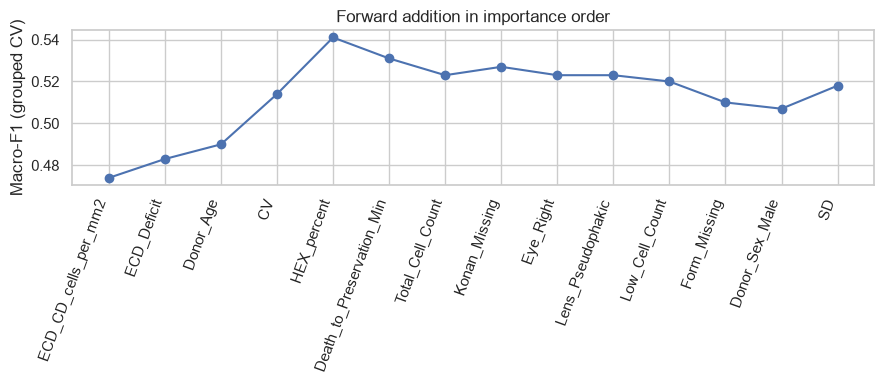

In [32]:
def cv_macro_f1(cols, data=train, target="Target_Class"):
    pred = cross_val_predict(rf_pipe(), data[cols], data[target], cv=cv, groups=data["Donor_Group"])
    return f1_score(data[target], pred, average="macro"), pred

order = perm_cls.index.tolist()
curve = []
for k in range(1, len(order) + 1):
    s, _ = cv_macro_f1(order[:k])
    curve.append({"k": k, "Added_feature": order[k - 1], "Macro_F1": round(s, 3)})
curve = pd.DataFrame(curve)
display(curve)

plt.figure(figsize=(9, 4))
plt.plot(curve["k"], curve["Macro_F1"], marker="o")
plt.xticks(curve["k"], curve["Added_feature"], rotation=70, ha="right")
plt.ylabel("Macro-F1 (grouped CV)"); plt.title("Forward addition in importance order")
plt.tight_layout(); plt.show()

In [33]:
groups_ablation = {
    "All reduced features": REDUCED,
    "Without Konan (raw+engineered)": [c for c in REDUCED if not FEATURE_GROUP[c].startswith("Konan")],
    "Without Donor": [c for c in REDUCED if FEATURE_GROUP[c] != "Donor"],
    "Without Missingness": [c for c in REDUCED if FEATURE_GROUP[c] != "Missingness"],
    "Without engineered Konan": [c for c in REDUCED if FEATURE_GROUP[c] != "Konan (engineered)"],
    "Konan raw only": [c for c in REDUCED if FEATURE_GROUP[c] == "Konan (raw)"],
}
abl = []
for name, cols in groups_ablation.items():
    s, pred = cv_macro_f1(cols)
    per = f1_score(train["Target_Class"], pred, average=None, labels=CLASS_ORDER)
    abl.append({"Feature_set": name, "n": len(cols), "Macro_F1": round(s, 3),
                **{f"F1_{c}": round(v, 3) for c, v in zip(CLASS_ORDER, per)}})
pd.DataFrame(abl)

,Feature_set,n,Macro_F1,F1_Normal,F1_Folds,F1_Guttata,F1_FECD/Endothelial
0,All reduced features,14,0.514,0.621,0.456,0.132,0.848
1,Without Konan (raw+engineered),7,0.303,0.530,0.350,0.056,0.276
2,Without Donor,9,0.495,0.595,0.422,0.113,0.848
3,Without Missingness,12,0.521,0.635,0.461,0.136,0.852
4,Without engineered Konan,12,0.518,0.646,0.472,0.106,0.848
5,Konan raw only,5,0.495,0.584,0.415,0.134,0.848


In [34]:
sev = train[train["Target_Severity"].isin(SEV_ORDER)].reset_index(drop=True)
print("Severity rows (train):", len(sev))
display(pd.crosstab(sev["Target_Class"], sev["Target_Severity"]))

perm_sev = grouped_perm_importance(sev, REDUCED, "Target_Severity").sort_values("Perm_Importance", ascending=False)
print("Permutation importance - severity (all diseased)")
display(perm_sev.round(4))

rows = []
for col in cont_feats:
    r = {"Feature": col}
    for cls in CLASS_ORDER[1:]:
        s = sev[sev["Target_Class"] == cls]
        a = s.loc[s["Target_Severity"] == "Moderate+Severe", col].dropna()
        b = s.loc[s["Target_Severity"] == "Mild", col].dropna()
        r[f"d_{cls}"] = round(cliffs_delta(a, b), 2) if len(a) > 2 and len(b) > 2 else np.nan
    rows.append(r)
sev_effect = pd.DataFrame(rows).set_index("Feature")
print("Cliff's delta, Moderate+Severe vs Mild, within each class")
display(sev_effect.reindex(sev_effect.abs().max(axis=1).sort_values(ascending=False).index))

s_all, p_all = cv_macro_f1(REDUCED, sev, "Target_Severity")
print(f"\nSeverity macro-F1 (all diseased, grouped CV): {s_all:.3f}")
print(classification_report(sev["Target_Severity"], p_all, zero_division=0))

Severity rows (train): 435


Target_Severity,Mild,Moderate+Severe
Target_Class,,
FECD/Endothelial,88,21
Folds,234,25
Guttata,58,9


Permutation importance - severity (all diseased)


,Perm_Importance,Std_across_folds,Positive_in_folds
ECD_Deficit,0.0324,0.0320,3
ECD_CD_cells_per_mm2,0.0227,0.0290,4
Total_Cell_Count,0.0015,0.0133,3
Low_Cell_Count,0.0000,0.0000,0
Lens_Pseudophakic,0.0000,0.0000,0
SD,-0.0005,0.0067,3
Eye_Right,-0.0025,0.0086,1
Konan_Missing,-0.0026,0.0051,0
Donor_Sex_Male,-0.0053,0.0081,1
HEX_percent,-0.0058,0.0048,0


Cliff's delta, Moderate+Severe vs Mild, within each class


,d_Folds,d_Guttata,d_FECD/Endothelial
Feature,,,
ECD_CD_cells_per_mm2,-0.20,-0.27,-0.62
ECD_Deficit,0.17,0.14,0.62
ECD_Age_Residual,-0.22,-0.25,-0.61
SD,0.10,0.54,0.60
log_SD,0.10,0.54,0.60
Total_Cell_Count,-0.07,-0.25,-0.56
Pleomorphism_Index,-0.02,0.54,0.13
SD_x_CV,0.03,0.54,0.50
CV,-0.06,0.47,0.19



Severity macro-F1 (all diseased, grouped CV): 0.634
                 precision    recall  f1-score   support

           Mild       0.90      0.98      0.94       380
Moderate+Severe       0.67      0.22      0.33        55

       accuracy                           0.89       435
      macro avg       0.78      0.60      0.63       435
   weighted avg       0.87      0.89      0.86       435



In [35]:
def rank(s): return s.rank(ascending=False)

summary = pd.DataFrame(index=REDUCED)
summary["Group"] = [FEATURE_GROUP[c] for c in REDUCED]
kh = uni_cont.set_index("Feature")["Kruskal_H"]
cv_ = uni_bin.set_index("Feature")["Cramers_V"]
summary["Univariate_rank"] = pd.concat([rank(kh), rank(cv_) + len(kh)]).reindex(REDUCED)
summary["MI_rank"] = rank(mi_all.reindex(REDUCED))
summary["Perm_rank"] = rank(perm_cls["Perm_Importance"])
summary["L1_nonzero_classes"] = coef["n_classes_nonzero"]
summary["Mean_rank"] = summary[["Univariate_rank", "MI_rank", "Perm_rank"]].mean(axis=1).round(1)
summary["Perm_Importance"] = perm_cls["Perm_Importance"].round(4)
summary["Severity_Perm"] = perm_sev["Perm_Importance"].round(4)
summary["Most_affected_class"] = perm_ovr.idxmax(axis=1)

def verdict(r):
    if r["Perm_Importance"] > 0.01 and r["Mean_rank"] <= 6: return "Strong"
    if r["Perm_Importance"] > 0.002 or r["Mean_rank"] <= 8: return "Moderate"
    return "Weak / none"
summary["Verdict"] = summary.apply(verdict, axis=1)
summary = summary.sort_values("Mean_rank")
summary

,Group,Univariate_rank,MI_rank,Perm_rank,L1_nonzero_classes,Mean_rank,Perm_Importance,Severity_Perm,Most_affected_class,Verdict
ECD_CD_cells_per_mm2,Konan (raw),2.0,1.0,1.0,3,1.3,0.0997,0.0227,FECD/Endothelial,Strong
ECD_Deficit,Konan (engineered),1.0,2.0,2.0,2,1.7,0.0931,0.0324,FECD/Endothelial,Strong
SD,Konan (raw),4.5,3.0,14.0,0,7.2,-0.0021,-0.0005,Guttata,Moderate
Total_Cell_Count,Konan (raw),10.0,5.0,7.0,2,7.3,0.0046,0.0015,Normal,Moderate
Donor_Age,Donor,7.0,13.0,3.0,2,7.7,0.0153,-0.0082,Folds,Moderate
Death_to_Preservation_Min,Donor,12.0,6.0,6.0,3,8.0,0.0053,-0.0065,Guttata,Moderate
CV,Konan (raw),9.0,13.0,4.0,2,8.7,0.0121,-0.0107,Folds,Moderate
HEX_percent,Konan (raw),11.0,13.0,5.0,1,9.7,0.0087,-0.0058,Normal,Moderate
Low_Cell_Count,Konan (engineered),15.0,4.0,11.0,1,10.0,0.0000,0.0000,Normal,Weak / none
Lens_Pseudophakic,Donor,13.0,10.0,10.0,1,11.0,0.0005,0.0000,Folds,Weak / none


In [36]:
SELECTED = summary.index[summary["Verdict"] != "Weak / none"].tolist()
print("Selected features:", SELECTED)
s_sel, p_sel = cv_macro_f1(SELECTED)
s_all, _ = cv_macro_f1(REDUCED)
print(f"Macro-F1  selected ({len(SELECTED)}): {s_sel:.3f}   |   all reduced ({len(REDUCED)}): {s_all:.3f}")
print(classification_report(train["Target_Class"], p_sel, zero_division=0))

data[["Tissue_ID", "Donor_Group", "Split", "Target_Class", "Target_Severity"] + FEATURES] \
    .to_csv(os.path.join(OUT_DIR, "Tabular_Features.csv"), index=False)
summary.to_csv(os.path.join(OUT_DIR, "Feature_Importance_Summary.csv"))
with open(os.path.join(OUT_DIR, "Selected_Features.json"), "w") as f:
    json.dump({"all": FEATURES, "reduced": REDUCED, "selected": SELECTED,
               "age_norm": {"intercept": float(intercept), "slope": float(slope)}}, f, indent=2)
print("Saved Tabular_Features.csv, Feature_Importance_Summary.csv, Selected_Features.json")

Selected features: ['ECD_CD_cells_per_mm2', 'ECD_Deficit', 'SD', 'Total_Cell_Count', 'Donor_Age', 'Death_to_Preservation_Min', 'CV', 'HEX_percent', 'Konan_Missing', 'Eye_Right']
Macro-F1  selected (10): 0.518   |   all reduced (14): 0.514
                  precision    recall  f1-score   support

FECD/Endothelial       0.79      0.90      0.84       109
           Folds       0.47      0.47      0.47       259
         Guttata       0.17      0.10      0.13        67
          Normal       0.62      0.64      0.63       403

        accuracy                           0.58       838
       macro avg       0.51      0.53      0.52       838
    weighted avg       0.56      0.58      0.57       838

Saved Tabular_Features.csv, Feature_Importance_Summary.csv, Selected_Features.json
